# To be completed at the Data Science Workshop and in your own time.

These set of examples we will help you get familiar with non parametric tests and correlations within a Jupyter notebook.   The questions coloured green are important practice for CA, particularly CA 2.

Before attempting these examples, please ensure you have read through [Chapter 6 Jupyter Notebook](https://github.com/itrharrison/PX4146/blob/main/Chapter6/Chapter6.ipynb) and have completed the Learning Central **Chapter 6 quiz**.

***

#  Credible Intervals

## <font color=#30a64d>Question</font>

Professor Dumbledore, studying the extinction of dragons, discovers a new set of egg remnants in an unexplored valley in Madagascar. The remnants are radio carbon dated and found to have the following ages in years:

2141.22, 1781.15, 1523.37, 1816.90, 1932.29, 1541.21, 720.782, 1026.22, 1687.22, 2460.59

Professor Snape however did a previous study in the next valley where he found eggs that were on average 1200 years old, following a normal distribution with standard deviation of 300 years.

1. What is the mean and standard deviation of the age of elephant bird eggs based on Dumbledore's data?

2. Write down an analytical expression for the mean of the ages that takes into account both Professor Dumbledore's new data and the previous age estimate from Professor Snape. Estimate the variance in your mean value.

3. Plot and discuss your results including a discussion of your methods.

### Answer

1663.0951999999997
479.91512789175545
1568.732944692688
135.42076756578965


/tmp/ipykernel_780/3107515039.py:31: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


Text(0, 0.5, 'PDF')

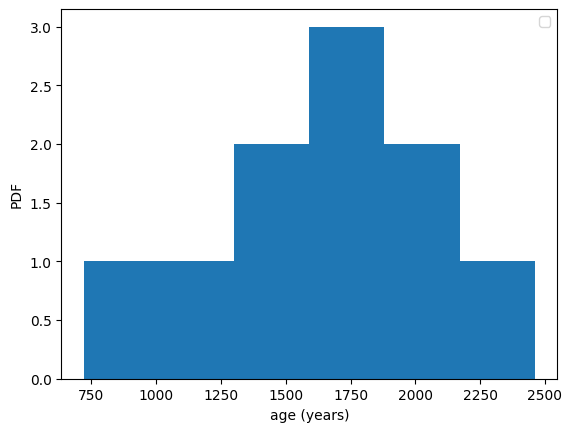

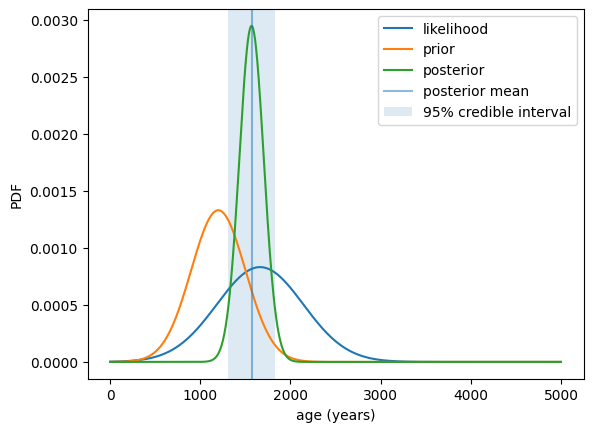

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

#1.
dumbledore = np.array([2141.22, 1781.15, 1523.37, 1816.90, 1932.29, 1541.21, 720.782, 1026.22, 1687.22, 2460.59])
x_bar = np.mean(dumbledore)
sigma = np.std(dumbledore)

print(x_bar)
print(sigma)

#2.
n = len(dumbledore)
mean_0 = 1200
sigma_0 = 300

posterior_mean = (sigma_0**2/(sigma_0**2+(sigma**2/n)))*x_bar+((sigma**2/n)/(sigma_0**2+(sigma**2/n)))*mean_0
posterior_variance_squared = ((sigma_0**2)*(sigma**2)/n)/(sigma_0**2+(sigma**2/n))
posterior_variance = np.sqrt(posterior_variance_squared)

print(posterior_mean)
print(posterior_variance)

#3.
d = np.linspace(0, 5000, 1000)
plt.figure()
plt.hist(dumbledore, bins=6)
plt.xlabel('age (years)')
plt.ylabel('PDF')
plt.legend()

plt.figure()
plt.plot(d, norm.pdf(d, x_bar, sigma),label='likelihood')
plt.plot(d, norm.pdf(d, mean_0, sigma_0),label='prior')
plt.plot(d, norm.pdf(d, posterior_mean, posterior_variance),label='posterior')
plt.axvline(posterior_mean,alpha=.5, label='posterior mean')
plt.axvspan(posterior_mean-1.96*posterior_variance, posterior_mean+1.96*posterior_variance, alpha=.15, label='95% credible interval')
plt.legend()
plt.xlabel('age (years)')
plt.ylabel('PDF')

*Your answer here.*

***